# 03 · EDA chi tiết — từ phát hiện đến hành động


- **EDA sơ bộ** (notebook 01, 02): dữ liệu có đủ sạch để dựng baseline chưa? Kết luận ở đó: **đủ**.
- **EDA chi tiết** (notebook này): "đào xới từng tấc đất". Xem phân phối thật của từng đặc trưng, ngoại lai có hợp logic không, tương quan và tương tác giữa các đặc trưng. Mục tiêu là tìm insight để **cải thiện dữ liệu**: tạo đặc trưng mới, làm sạch, xử lý phân phối lệch, encode, phát hiện rò rỉ.

EDA trong AI/ML dùng để tìm liên hệ giữa các trường dữ liệu, từ đó chọn **hướng đi, thuật toán và feature engineering**. Vì vậy mục nào cũng kết thúc bằng khối **→ Hành động**.

**Phần A. Panel ngân hàng–quý** (dự báo và xếp hạng)
1. Phân phối thật của mục tiêu và đặc trưng
2. Ngoại lai có hợp logic không?
3. Tương quan giữa các đặc trưng
4. Liên hệ và tương tác với mục tiêu
5. Rò rỉ dữ liệu
6. Dữ liệu có cụm không?

**Phần B. Review app** (NLP)

7. Độ dài và số sao
8. Cách viết và khía cạnh

**Phần C. Tổng hợp: phát hiện → hành động**

Các phép tính nặng (kiểm chéo, kiểm định) lấy từ `data/model/eda_ml/` do `python -m experiments.eda_ml` sinh ra.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "model").exists())
DATA = ROOT / "data"
E = DATA / "model" / "eda_ml"          # kết quả tính sẵn của experiments/eda_ml.py
if not (E / "facts.json").exists():
    raise FileNotFoundError("Chưa có data/model/eda_ml/. Chạy trước: python -m experiments.eda_ml (~3 phút)")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a94", "#e34948"

TARGETS = {"nim_ttm_percent": "NIM", "cof_ttm_percent": "COF", "npl_percent": "NPL",
           "casa_percent": "CASA", "ldr_computed_percent": "LDR", "roe_ttm_percent": "ROE"}

f = pd.read_csv(DATA / "model" / "features_selected.csv", encoding="utf-8-sig")
mas = pd.read_csv(DATA / "vnstock_financial" / "ratio_mas_ttm.csv", encoding="utf-8-sig")[
    ["ticker", "period", "cof_quarter_percent", "nim_quarter_percent"]]
f = f.merge(mas, on=["ticker", "period"], how="left").sort_values(["ticker", "period"]).reset_index(drop=True)
p = f[f.period >= "2019-Q1"].copy()          # EDA sơ bộ: 2018 thiếu nhiều nên bắt đầu từ 2019
facts = json.load(open(E / "facts.json", encoding="utf-8"))
print(f"Panel dùng cho EDA chi tiết: {len(p)} NH-quý, {p.ticker.nunique()} NH, {p.period.min()} → {p.period.max()}")

Panel dùng cho EDA chi tiết: 660 NH-quý, 22 NH, 2019-Q1 → 2026-Q2


# Phần A. Panel ngân hàng–quý

## 1. Phân phối thật của mục tiêu và đặc trưng

**Câu hỏi:** Phân phối của 6 mục tiêu và của thay đổi theo quý có lệch không, đuôi có dày không? Đặc trưng nào cần biến đổi?

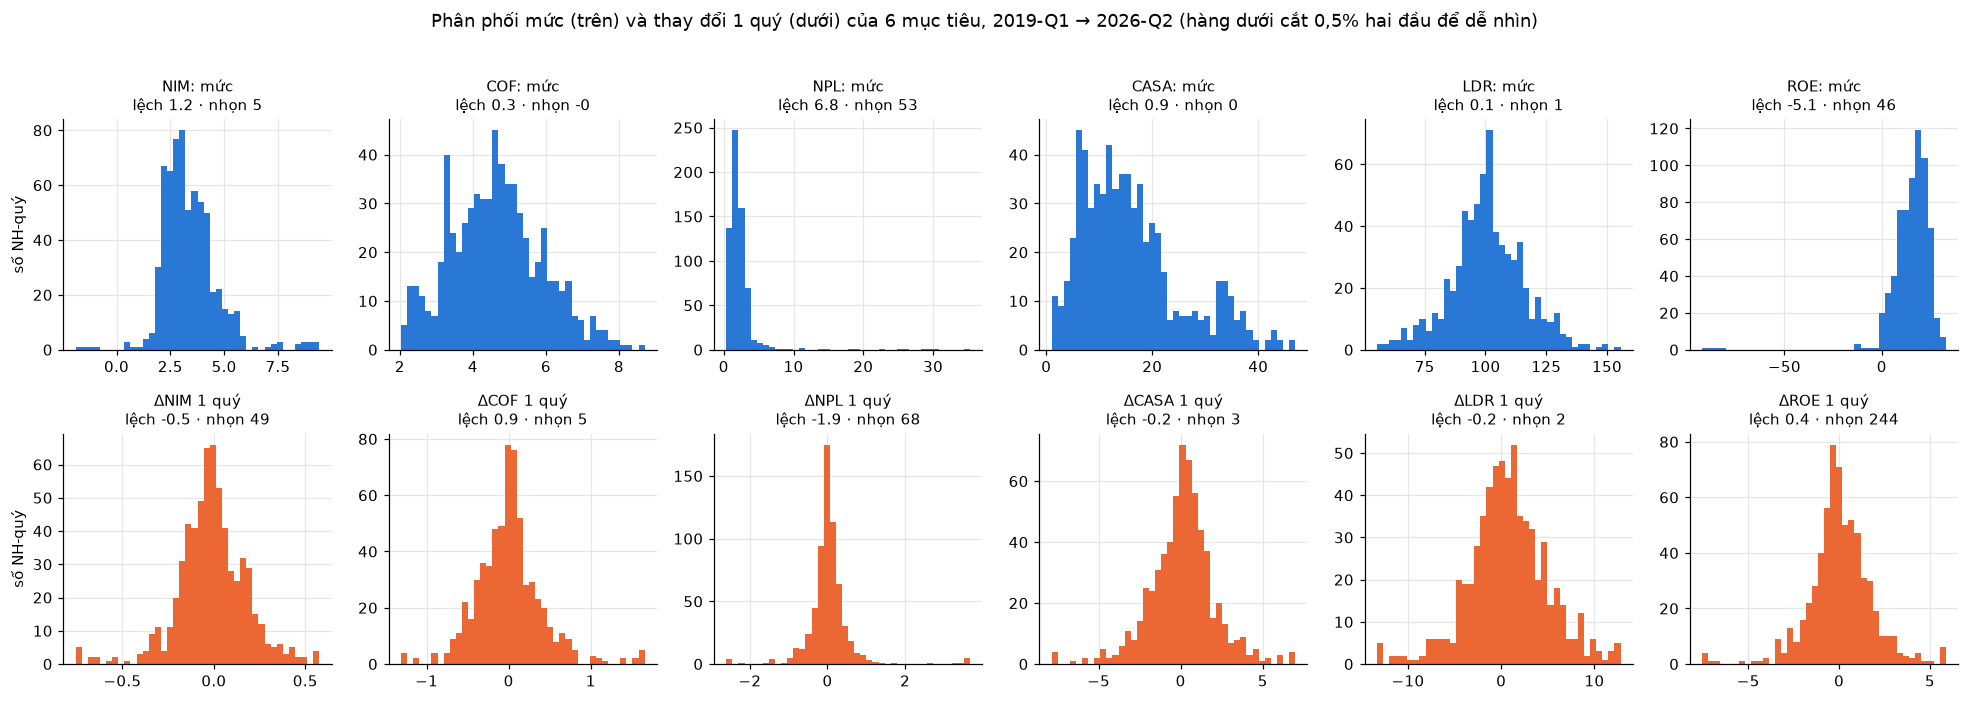

In [2]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6.2))
for j, (c, lab) in enumerate(TARGETS.items()):
    x = p[c].dropna()
    d = p.groupby("ticker")[c].diff().dropna()
    axes[0, j].hist(x, bins=40, color=BLUE)
    axes[0, j].set_title(f"{lab}: mức\nlệch {x.skew():.1f} · nhọn {x.kurt():.0f}", fontsize=10)
    lo, hi = d.quantile([0.005, 0.995])
    axes[1, j].hist(d.clip(lo, hi), bins=40, color=ORANGE)
    axes[1, j].set_title(f"Δ{lab} 1 quý\nlệch {d.skew():.1f} · nhọn {d.kurt():.0f}", fontsize=10)
axes[0, 0].set_ylabel("số NH-quý")
axes[1, 0].set_ylabel("số NH-quý")
fig.suptitle("Phân phối mức (trên) và thay đổi 1 quý (dưới) của 6 mục tiêu, 2019-Q1 → 2026-Q2 (hàng dưới cắt 0,5% hai đầu để dễ nhìn)", y=1.02)
plt.tight_layout()
plt.show()

In [3]:
u = pd.read_csv(E / "univariate.csv", encoding="utf-8-sig")
cont = u[u.n_unique > 2]
print(f"{len(cont)} đặc trưng liên tục: {int((cont['skew'].abs() <= 1).sum())} gần đối xứng, "
      f"{int((cont['skew'].abs() > 1).sum())} lệch |skew| > 1; Yeo-Johnson đưa "
      f"{int(((cont['skew'].abs() > 1) & (cont.skew_yeojohnson.abs() < 0.5)).sum())} biến lệch về |skew| < 0,5.")
print("\nHành động đề xuất cho mô hình tuyến tính / kNN / PCA / TOPSIS:")
print(u.linear_action.value_counts().to_string())
u.loc[cont["skew"].abs().sort_values(ascending=False).index[:10],
      ["feature", "skew", "skew_yeojohnson", "kurtosis", "outlier_pct", "top_outlier_bank"]].round(2)

87 đặc trưng liên tục: 48 gần đối xứng, 39 lệch |skew| > 1; Yeo-Johnson đưa 27 biến lệch về |skew| < 0,5.

Hành động đề xuất cho mô hình tuyến tính / kNN / PCA / TOPSIS:
linear_action
chỉ chuẩn hóa z                   47
Yeo-Johnson                       25
Yeo-Johnson + winsorize p1/p99    14
giữ 0/1                            6
winsorize p1/p99                   1


,feature,skew,skew_yeojohnson,kurtosis,outlier_pct,top_outlier_bank
91,cir_quarter_percent,24.66,-0.10,620.96,0.91,NVB
23,pe,20.11,4.39,446.53,5.37,NVB
90,roe_quarter_percent,-16.62,0.25,364.61,0.45,NVB
1,npl_percent,6.77,-0.05,52.78,2.59,NVB
14,roe_ttm_percent,-5.13,-0.08,45.15,0.61,NVB
79,dividend_yield,4.01,2.47,15.88,0.00,NaN
33,dividend_payout_ttm_pct,3.85,0.79,16.32,8.81,BAB
21,cir_ttm_pct,3.11,0.00,19.70,0.61,NVB
66,ind_share_F_asof_pct,2.67,-0.01,9.00,3.73,NVB
75,corp_bond_to_assets_pct,2.66,0.32,9.06,4.41,TCB


**Nhận xét**
- COF, LDR, CASA có mức gần đối xứng. NPL và ROE lệch rất mạnh, và đuôi dài đều nằm ở một ngân hàng (xem mục 2).
- Thay đổi theo quý của cả 6 chỉ tiêu có đuôi rất dày: phần lớn các quý gần như không đổi, thỉnh thoảng có một cú nhảy lớn.
- Khoảng 4/10 đặc trưng lệch; Yeo-Johnson sửa được phần lớn.

**→ Hành động**
- *Xử lý phân phối lệch*: Yeo-Johnson cho biến lệch, winsorize p1/p99 cho biến nhiều ngoại lai, fit trên tập train. Chỉ cần với mô hình tuyến tính, kNN, PCA và chuẩn hóa TOPSIS. Mô hình cây giữ nguyên.
- *Thuật toán*: đuôi dày thì dùng hàm mất mát MAE/Huber và baseline tính bằng trung vị; tránh MSE thuần.

## 2. Ngoại lai có hợp logic không?



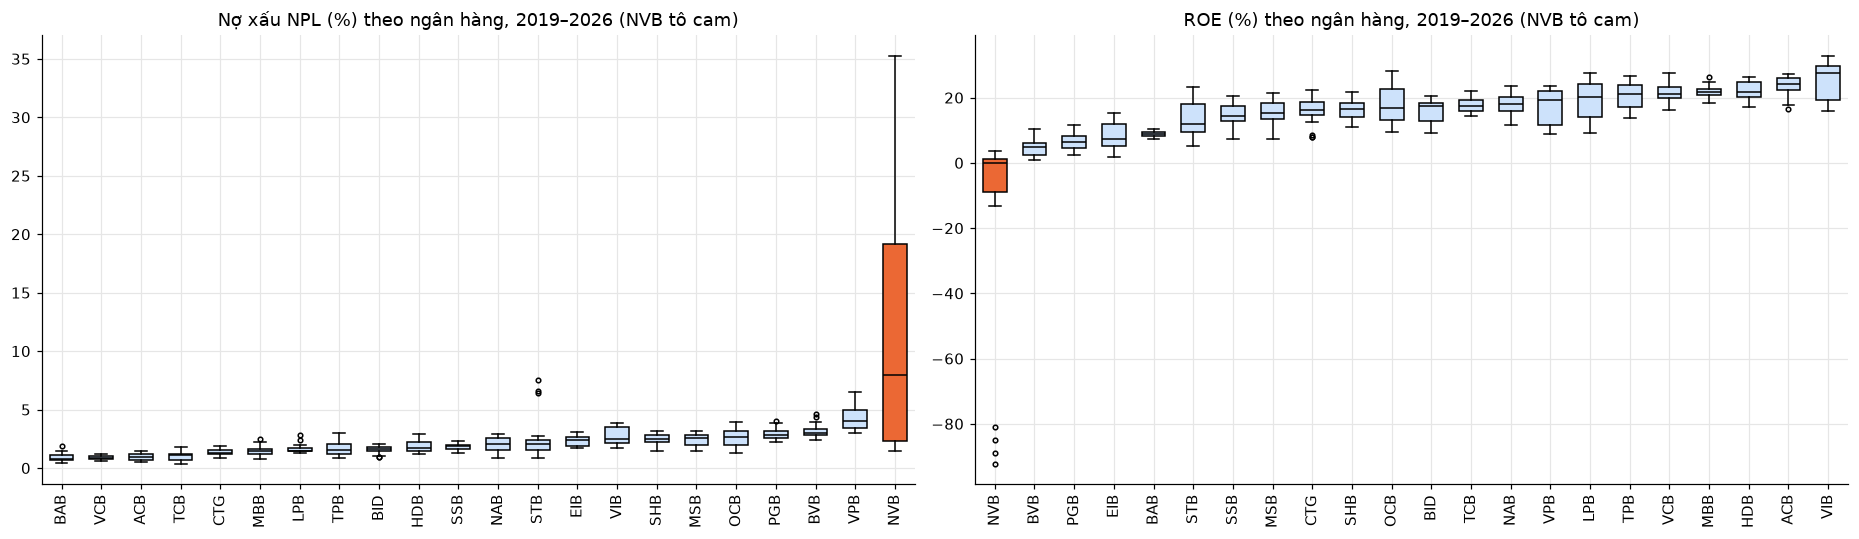

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, (c, lab) in zip(axes, [("npl_percent", "Nợ xấu NPL (%)"), ("roe_ttm_percent", "ROE (%)")]):
    order = p.groupby("ticker")[c].median().sort_values().index
    bp = ax.boxplot([p.loc[p.ticker == t, c].dropna() for t in order], patch_artist=True, widths=0.6,
                    medianprops={"color": "black"}, flierprops={"markersize": 3})
    for box, t in zip(bp["boxes"], order):
        box.set_facecolor(ORANGE if t == "NVB" else "#cde2fb")
    ax.set_xticks(range(1, len(order) + 1), order, rotation=90)
    ax.set_title(f"{lab} theo ngân hàng, 2019–2026 (NVB tô cam)")
plt.tight_layout()
plt.show()

In [5]:
num = [c for c in p.select_dtypes("number").columns if p[c].nunique() > 2]
cnt = pd.Series(0, index=sorted(p.ticker.unique()))
for c in num:
    v = p[c]
    q1, q3 = v.quantile([0.25, 0.75])
    if q3 - q1 <= 0:
        continue
    out = (v < q1 - 3 * (q3 - q1)) | (v > q3 + 3 * (q3 - q1))
    cnt = cnt.add(p.loc[out, "ticker"].value_counts(), fill_value=0)
share = (cnt / cnt.sum()).sort_values(ascending=False)
print(f"Tổng số ô ngoại lai (ngoài 3×IQR) trên {len(num)} đặc trưng: {int(cnt.sum())}")
print(f"NVB chiếm {share['NVB']:.0%} số ô ngoại lai, dù chỉ là 1/22 NH")
share.head(8).round(3)

Tổng số ô ngoại lai (ngoài 3×IQR) trên 84 đặc trưng: 716
NVB chiếm 20% số ô ngoại lai, dù chỉ là 1/22 NH


NVB    0.200
VPB    0.122
BID    0.080
CTG    0.077
VCB    0.074
MBB    0.059
BAB    0.053
ACB    0.047
dtype: float64

**Nhận xét**
- Ngoại lai không rải đều. NVB chiếm khoảng 20% số ô ngoại lai, gấp 4 lần phần của một NH trong 22 NH; tiếp theo là VPB (~12%). Ở NVB đó là NPL 35%, ROE âm sâu, CIR vượt 900%.
- Đây là **số thật**: NVB đang tái cơ cấu, báo chí đưa đúng các con số này, và cổng `validate` đã xếp chúng vào mức WARN chứ không phải ERROR.


**→ Hành động**
- *Làm sạch*: **không xóa** NVB. Xóa là mất một trường hợp thật mà người dùng cần được cảnh báo.
- *Thuật toán*: dùng đo lường bền với ngoại lai (Spearman, MAE, winsorize khi chuẩn hóa). Khi viết, báo kết quả có và không có NVB.
- *Xếp hạng*: chuẩn hóa min-max bị NVB chiếm thang đo, nên phải winsorize hoặc chuẩn hóa theo hạng.

## 3. Tương quan giữa các đặc trưng

**Câu hỏi:** Đặc trưng nào trùng thông tin? Quan hệ **giữa các ngân hàng** (so sánh ngân hàng này với ngân hàng khác) có giống quan hệ **trong một ngân hàng theo thời gian** không?

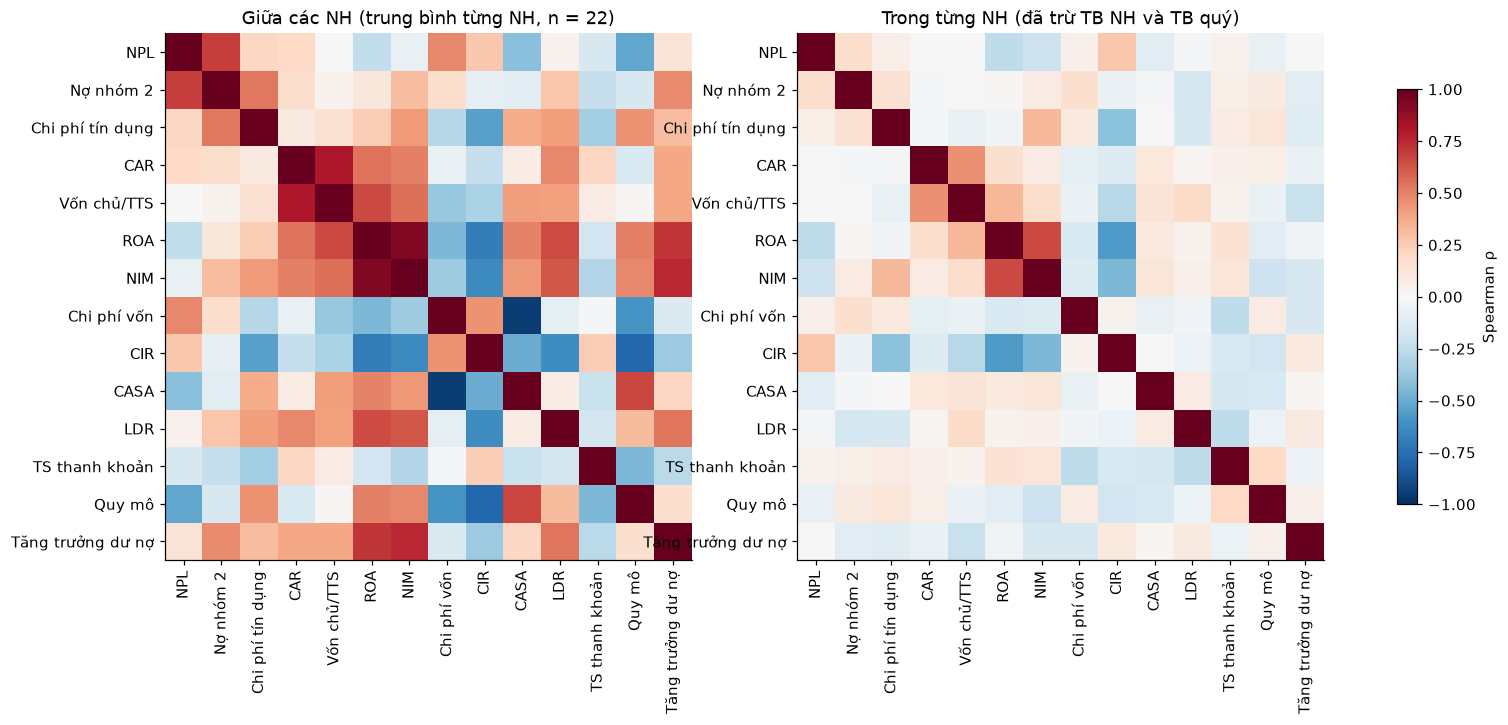

CASA – chi phí vốn: giữa NH -0.95, trong NH -0.08
ROA – NIM:          giữa NH +0.92, trong NH +0.66


In [6]:
COLS = {"npl_percent": "NPL", "loans_g2_percent": "Nợ nhóm 2", "credit_cost_ttm_pct": "Chi phí tín dụng",
        "car_asof_percent": "CAR", "equity_to_assets_pct": "Vốn chủ/TTS", "roa_ttm_percent": "ROA",
        "nim_ttm_percent": "NIM", "cof_ttm_percent": "Chi phí vốn", "cir_ttm_pct": "CIR", "casa_percent": "CASA",
        "ldr_computed_percent": "LDR", "liquid_assets_pct": "TS thanh khoản", "log_total_assets": "Quy mô",
        "loans_yoy_percent": "Tăng trưởng dư nợ"}
cols = list(COLS)
between = p.groupby("ticker")[cols].mean().rank().corr()
dem = p[cols] - p.groupby("ticker")[cols].transform("mean")
dem = dem - dem.groupby(p.period).transform("mean")
within = dem.rank().corr()
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, C, title in [(axes[0], between, "Giữa các NH (trung bình từng NH, n = 22)"),
                     (axes[1], within, "Trong từng NH (đã trừ TB NH và TB quý)")]:
    im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), [COLS[c] for c in cols], rotation=90)
    ax.set_yticks(range(len(cols)), [COLS[c] for c in cols])
    ax.grid(False)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.7, label="Spearman ρ")
plt.show()
print(f"CASA – chi phí vốn: giữa NH {between.loc['casa_percent', 'cof_ttm_percent']:+.2f}, trong NH {within.loc['casa_percent', 'cof_ttm_percent']:+.2f}")
print(f"ROA – NIM:          giữa NH {between.loc['roa_ttm_percent', 'nim_ttm_percent']:+.2f}, trong NH {within.loc['roa_ttm_percent', 'nim_ttm_percent']:+.2f}")

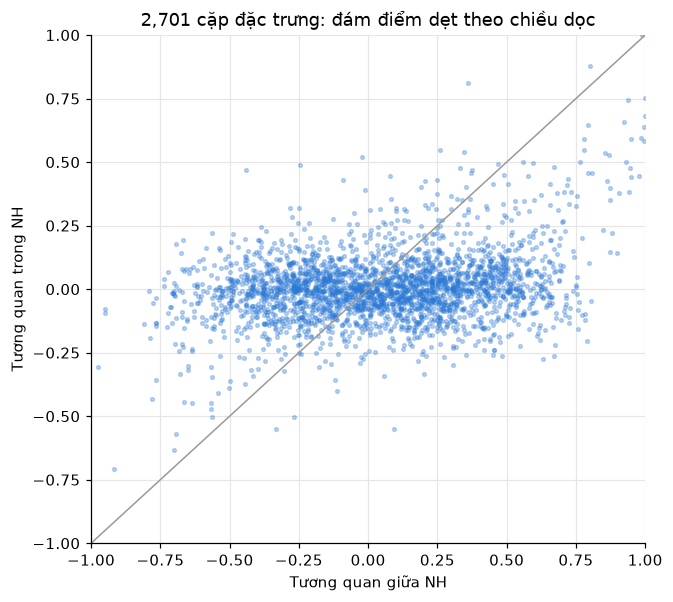

Trung vị |ρ|: giữa NH 0.26 · trong NH 0.06
Cặp |ρ| ≥ 0,7: giữa NH 95 · trong NH 6
74 đặc trưng theo NH-quý chỉ mang 8 chiều (80% phương sai) khi so giữa NH; 29 biến lõi mang 14 chiều khi theo dõi trong NH


,feature,cluster,vif
13,roa_ttm_percent,22,12.5
14,roe_ttm_percent,22,12.4
24,nim_quarter_percent,17,8.5
12,nim_ttm_percent,17,7.8
26,roe_quarter_percent,23,5.1


In [7]:
pairs = pd.read_csv(E / "corr_pairs_all.csv", encoding="utf-8-sig")
d = facts["dims"]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(pairs.between, pairs.within, s=6, alpha=0.3, color=BLUE)
ax.plot([-1, 1], [-1, 1], color=GRAY, lw=1)
ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
ax.set_xlabel("Tương quan giữa NH"); ax.set_ylabel("Tương quan trong NH")
ax.set_title(f"{len(pairs):,} cặp đặc trưng: đám điểm dẹt theo chiều dọc")
plt.show()
print(f"Trung vị |ρ|: giữa NH {d['median_abs_between']:.2f} · trong NH {d['median_abs_within']:.2f}")
print(f"Cặp |ρ| ≥ 0,7: giữa NH {d['pairs_between_07']} · trong NH {d['pairs_within_07']}")
print(f"{d['n_varying']} đặc trưng theo NH-quý chỉ mang {d['between_all_80']} chiều (80% phương sai) khi so giữa NH; "
      f"{d['n_core']} biến lõi mang {d['within_core_80']} chiều khi theo dõi trong NH")
vif = pd.read_csv(E / "clusters_within_core.csv", encoding="utf-8-sig")
vif[vif.vif >= 5].sort_values("vif", ascending=False).round(1)

**Nhận xét**
- **Giữa các ngân hàng**, nhiều đặc trưng gần như là một: CASA cao thì chi phí vốn thấp (ρ ≈ −0,95), NH lớn thì CIR thấp, ROA đi cùng NIM. Khoảng 74 đặc trưng thực chất chỉ mang ~8 chiều thông tin.
- **Trong từng ngân hàng** theo thời gian, phần lớn các quan hệ đó biến mất: trung vị |ρ| chỉ khoảng 0,06, CASA–chi phí vốn từ −0,95 còn −0,08. Chỉ các quan hệ kế toán còn giữ, như ROA–NIM (0,92 → 0,66). VIF chỉ cao ở cặp ROE/ROA và NIM TTM/NIM quý.
- Cùng một cặp biến có thể mang hai ý nghĩa khác nhau. Quan hệ "giữa NH" không dùng được cho mô hình chuỗi thời gian, và ngược lại.

**→ Hành động**
- *Xếp hạng* (so giữa các NH): trong mỗi cụm trùng chỉ giữ **một** tiêu chí, ví dụ CASA hoặc chi phí vốn, ROA hoặc NIM; nếu không, một chiều thông tin bị tính hai lần.
- *Dự báo* (trong NH): giữ phần lớn đặc trưng, bỏ một trong ROE/ROA; Ridge đủ xử lý phần tương quan còn lại.
- *Hướng đi*: bài toán chính là **so sánh cắt ngang**; chuỗi thời gian là phần phụ.

## 4. Liên hệ và tương tác với mục tiêu

**Câu hỏi:** Đặc trưng nào báo trước thay đổi của mục tiêu ở quý sau? Có cấu trúc thời gian nào (mùa vụ, độ trễ, cách tính TTM) có thể biến thành đặc trưng mới không?

### 4.1. Đặc trưng đi cùng thay đổi mục tiêu quý sau

Đặc trưng quý t đã trừ trung bình *quá khứ* của NH, so với thay đổi mục tiêu t → t+1. Chỉ giữ những đặc trưng cùng dấu ở cả hai nửa giai đoạn (trước và sau 2022-Q2).

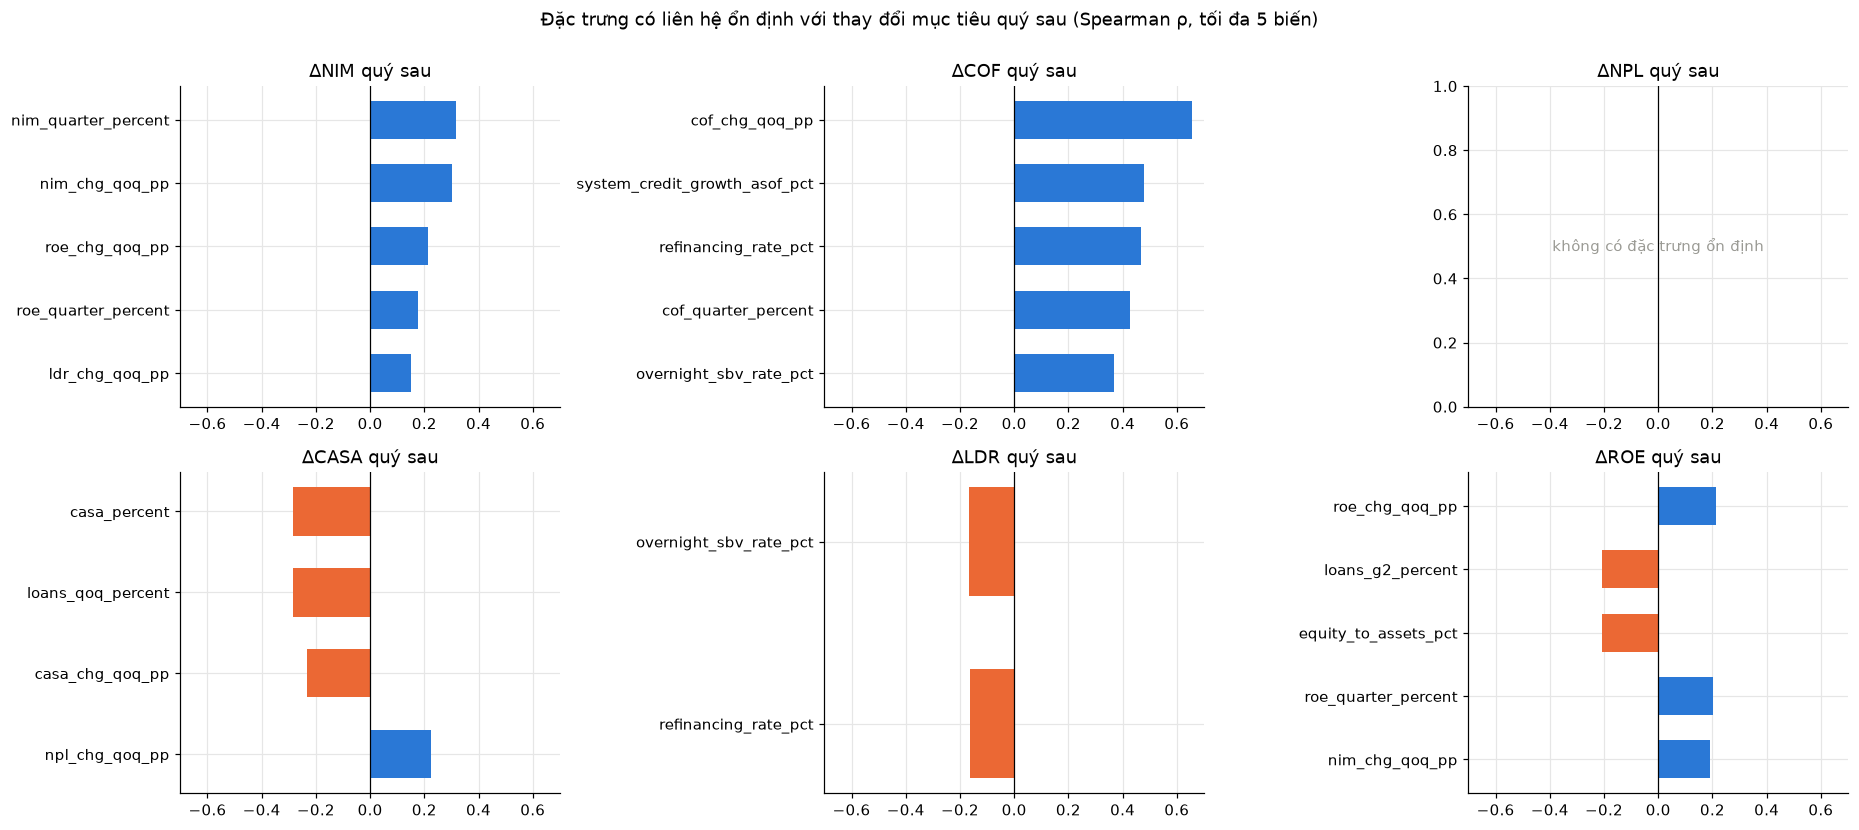

Số đặc trưng ổn định theo mục tiêu × tầm:
h       1   2   4
label            
CASA    4   8  11
COF    11  11  18
LDR     2   6   9
NIM     5   4   0
NPL     0   2   9
ROE     7   8   8


In [8]:
ft = pd.read_csv(E / "feature_target.csv", encoding="utf-8-sig")
top = ft[(ft.h == 1) & ft.stable].sort_values("rho", key=abs, ascending=False).groupby("label").head(5)
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, lab in zip(axes.flat, ["NIM", "COF", "NPL", "CASA", "LDR", "ROE"]):
    t = top[top.label == lab].sort_values("rho", key=abs)
    if t.empty:
        ax.text(0.5, 0.5, "không có đặc trưng ổn định", ha="center", va="center", transform=ax.transAxes, color=GRAY)
    else:
        ax.barh(t.feature, t.rho, color=[BLUE if r > 0 else ORANGE for r in t.rho], height=0.6)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-0.7, 0.7)
    ax.set_title(f"Δ{lab} quý sau")
fig.suptitle("Đặc trưng có liên hệ ổn định với thay đổi mục tiêu quý sau (Spearman ρ, tối đa 5 biến)", y=1.0)
plt.tight_layout()
plt.show()
print("Số đặc trưng ổn định theo mục tiêu × tầm:")
print(ft[ft.stable].groupby(["label", "h"]).size().unstack(fill_value=0))

### 4.2. Ba cấu trúc thời gian có thể biến thành đặc trưng

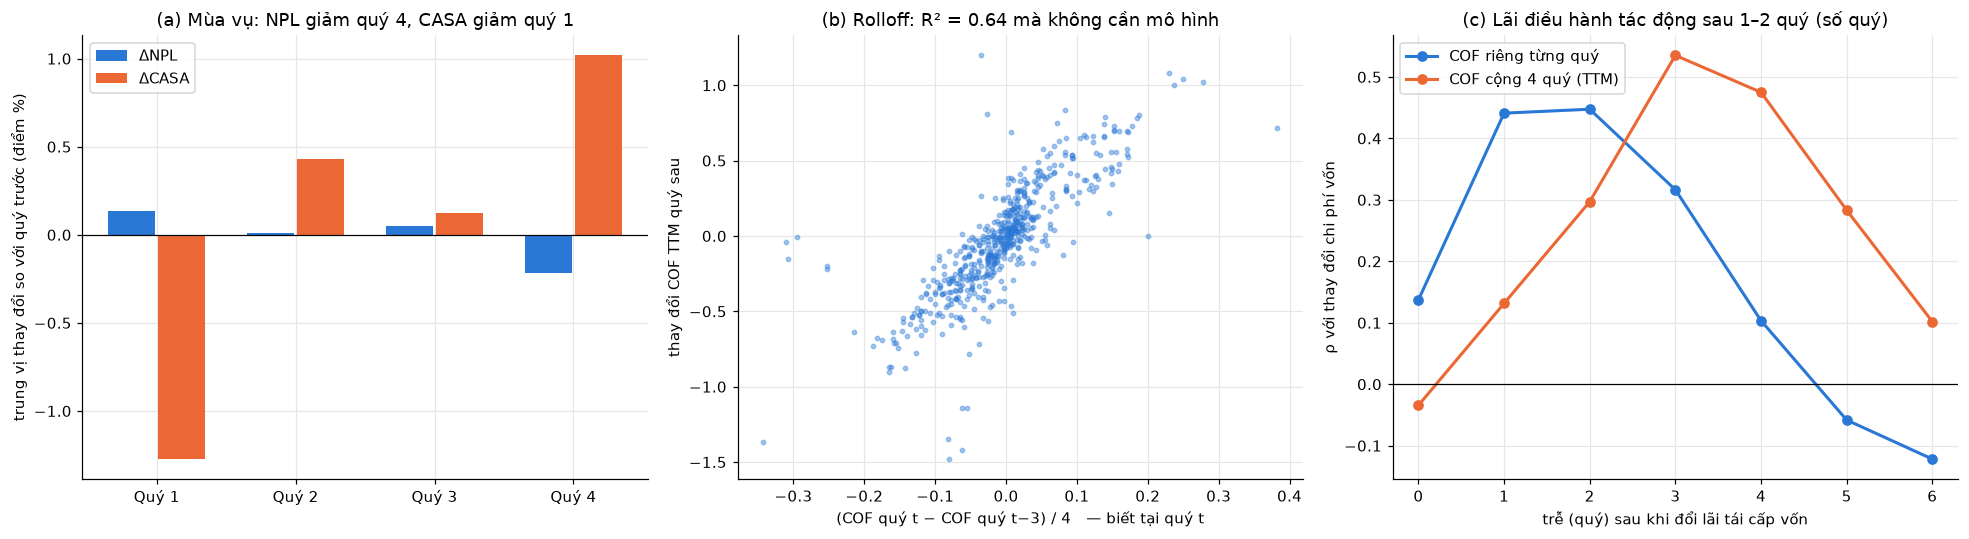

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Mùa vụ: thay đổi NPL và CASA theo quý trong năm
for k, (c, lab, col) in enumerate([("npl_percent", "ΔNPL", BLUE), ("casa_percent", "ΔCASA", ORANGE)]):
    dd = p.assign(d=p.groupby("ticker")[c].diff(), q=p.period.str[-1].astype(int)).dropna(subset=["d"])
    lo, hi = dd.d.quantile([0.02, 0.98])
    med = dd.assign(d=dd.d.clip(lo, hi)).groupby("q").d.median()
    axes[0].bar(np.arange(1, 5) + (k - 0.5) * 0.36, med.values, width=0.34, color=col, label=lab)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xticks(range(1, 5), ["Quý 1", "Quý 2", "Quý 3", "Quý 4"])
axes[0].set_ylabel("trung vị thay đổi so với quý trước (điểm %)")
axes[0].set_title("(a) Mùa vụ: NPL giảm quý 4, CASA giảm quý 1")
axes[0].legend()

# (b) Rolloff: thay đổi COF TTM quý sau so với phần đã biết (quý t - quý t-3)/4
g = p.groupby("ticker")
dnext = g.cof_ttm_percent.shift(-1) - p.cof_ttm_percent
known = (p.cof_quarter_percent - g.cof_quarter_percent.shift(3)) / 4
ok = dnext.notna() & known.notna()
r = np.corrcoef(known[ok], dnext[ok])[0, 1]
axes[1].scatter(known[ok], dnext[ok], s=8, alpha=0.4, color=BLUE)
axes[1].set_xlabel("(COF quý t − COF quý t−3) / 4   — biết tại quý t")
axes[1].set_ylabel("thay đổi COF TTM quý sau")
axes[1].set_title(f"(b) Rolloff: R² = {r ** 2:.2f} mà không cần mô hình")

# (c) Độ trễ lãi điều hành -> chi phí vốn
ll = pd.read_csv(DATA / "model" / "eda" / "leadlag.csv", encoding="utf-8-sig")
for c, lab, col in [("cof_quarter_percent", "COF riêng từng quý", BLUE), ("cof_ttm_percent", "COF cộng 4 quý (TTM)", ORANGE)]:
    s = ll[ll.feature == c]
    axes[2].plot(s.lag, s.rho_panel, marker="o", color=col, lw=2, label=lab)
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_xlabel("trễ (quý) sau khi đổi lãi tái cấp vốn")
axes[2].set_ylabel("ρ với thay đổi chi phí vốn")
axes[2].set_title("(c) Lãi điều hành tác động sau 1–2 quý (số quý)")
axes[2].legend()
plt.tight_layout()
plt.show()

**Nhận xét**
- Số đặc trưng có liên hệ ổn định rất ít: 0–18 cho mỗi mục tiêu × tầm; NPL tầm 1 quý không có đặc trưng nào. Nhiều nhất là COF, nhờ các biến vĩ mô (lãi điều hành, tăng trưởng tín dụng).
- **Mùa vụ**: NPL giảm ở quý 4 rồi tăng lại quý 1; CASA giảm ở quý 1.
- **Rolloff**: TTM là tổng 4 quý, nên thay đổi TTM quý sau = (quý mới vào − quý rơi ra)/4. Quý rơi ra đã biết tại t, nên riêng phần này giải thích khoảng 64% thay đổi COF quý sau.
- **Độ trễ**: tính trên số riêng từng quý, chi phí vốn phản ứng với lãi điều hành sau 1–2 quý. Đỉnh 3 quý khi đo trên TTM chỉ là do cộng dồn.

**→ Hành động (tạo đặc trưng mới)**
- Số riêng từng quý (NIM, COF, ROE, CIR, lợi suất) lấy từ MAS, và **số hạng rolloff** (x<sub>t</sub> − x<sub>t−3</sub>)/4.
- **Biến quý trong năm** (one-hot 3 cột) cho NPL, CASA, tăng trưởng dư nợ.
- **Lãi tái cấp vốn trễ 1 và 2 quý**.
- *Thuật toán*: vì tín hiệu ít, baseline có cấu trúc (naive, mùa vụ, drift, rolloff) là mô hình chính; học máy chỉ là mô hình thách thức.

## 5. Rò rỉ dữ liệu

**Câu hỏi:** Chia train/test kiểu nào thì kết quả đáng tin?


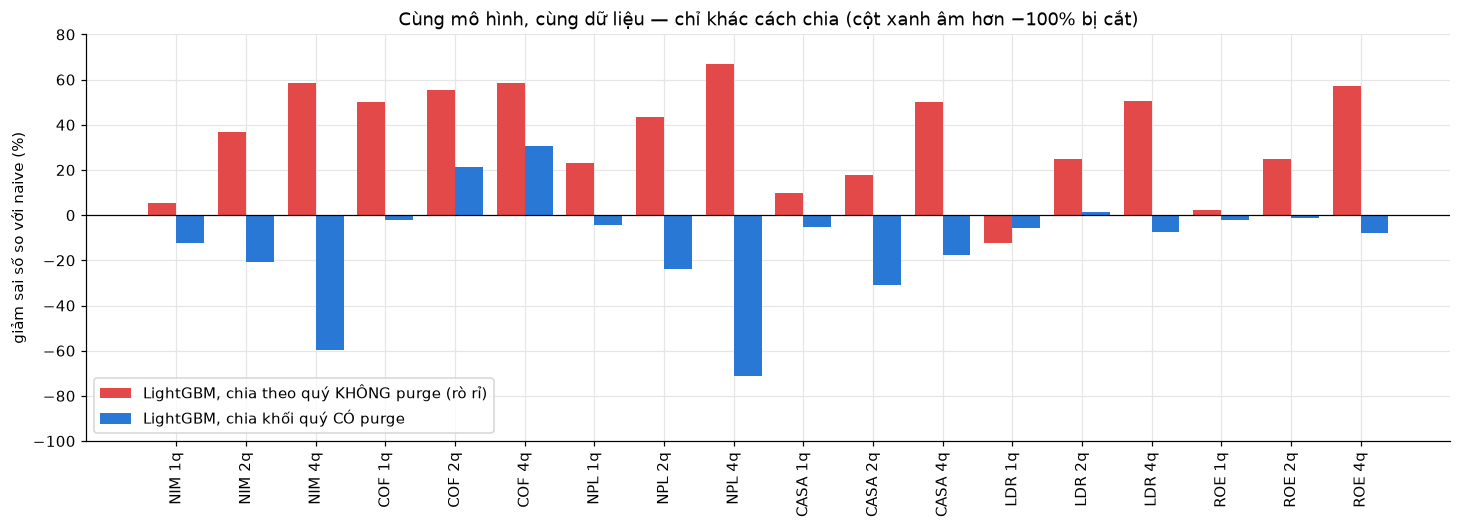

,label,h,purge_gap,skill_lgbm_leaky,skill_lgbm_all,skill_seasonal,skill_ridge_stable
0,NIM,1,4,0.06,-0.12,-0.08,-0.08
1,NIM,2,5,0.37,-0.21,-0.11,-0.21
2,NIM,4,7,0.58,-0.60,-0.35,-0.35
3,COF,1,4,0.50,-0.02,0.04,-0.13
4,COF,2,5,0.56,0.21,0.20,-0.55
5,COF,4,7,0.58,0.30,0.26,-0.78
6,NPL,1,1,0.23,-0.05,0.04,0.04
7,NPL,2,2,0.43,-0.24,-0.01,-0.52
8,NPL,4,4,0.67,-0.71,-0.08,-0.59
9,CASA,1,1,0.10,-0.05,0.15,0.10


In [10]:
ceil = pd.read_csv(E / "signal_ceiling.csv", encoding="utf-8-sig")
ceil["ô"] = ceil.label + " " + ceil.h.astype(str) + "q"
fig, ax = plt.subplots(figsize=(16, 4.8))
x = np.arange(len(ceil))
ax.bar(x - 0.2, 100 * ceil.skill_lgbm_leaky, width=0.4, color=RED, label="LightGBM, chia theo quý KHÔNG purge (rò rỉ)")
ax.bar(x + 0.2, 100 * ceil.skill_lgbm_all.clip(lower=-1), width=0.4, color=BLUE, label="LightGBM, chia khối quý CÓ purge")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, ceil["ô"], rotation=90)
ax.set_ylabel("giảm sai số so với naive (%)")
ax.set_ylim(-100, 80)
ax.set_title("Cùng mô hình, cùng dữ liệu — chỉ khác cách chia (cột xanh âm hơn −100% bị cắt)")
ax.legend(loc="lower left")
plt.show()
ceil[["label", "h", "purge_gap", "skill_lgbm_leaky", "skill_lgbm_all", "skill_seasonal", "skill_ridge_stable"]].round(2)

**Nhận xét**
- Chia theo quý mà không purge, LightGBM "thắng" naive tới +67% ở tầm 2–4 quý.
- Khi bỏ khỏi tập train các quý có thay đổi chồng lên tập test (purge h quý, TTM thêm 3), phần lớn các ô rơi xuống dưới naive. Chỉ COF còn tín hiệu, và mức đó ngang drift.
- Ngoài ra còn rò rỉ cùng quý: một số đặc trưng như `cof_chg_qoq_pp` được tính từ chính mục tiêu trong cùng quý (đánh dấu ⚠️ trong bảng ý nghĩa đặc trưng ở notebook 01).

**→ Hành động**
- *Đánh giá*: walk-forward theo thời gian, hoặc kiểm chéo khối có purge. **Không bao giờ** chia ngẫu nhiên.
- *Tạo đặc trưng*: các đặc trưng ⚠️ rò rỉ cùng quý chỉ được dùng ở dạng trễ 1 quý.

## 6. Dữ liệu có cụm không?

**Câu hỏi:** Có nên chia 22 ngân hàng thành nhóm bằng k-means rồi dùng nhóm làm đặc trưng hay làm tầng lọc cho xếp hạng không?

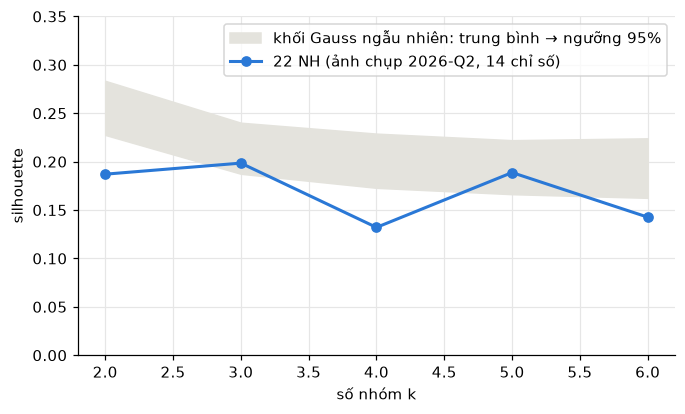

Hopkins (3 thành phần chính): 0.58 · ngưỡng 95% của khối Gauss: 0.57


,k,silhouette,null_mean,null_p95,p
0,2,0.187,0.228,0.283,0.90
1,3,0.198,0.187,0.240,0.35
2,4,0.132,0.173,0.229,0.94
3,5,0.189,0.166,0.222,0.22
4,6,0.143,0.163,0.224,0.76


In [11]:
cl = pd.read_csv(E / "cluster_tendency.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(cl.k, cl.null_mean, cl.null_p95, color="#e4e3dd", label="khối Gauss ngẫu nhiên: trung bình → ngưỡng 95%")
ax.plot(cl.k, cl.silhouette, marker="o", color=BLUE, lw=2, label="22 NH (ảnh chụp 2026-Q2, 14 chỉ số)")
ax.set_xlabel("số nhóm k"); ax.set_ylabel("silhouette"); ax.set_ylim(0, 0.35)
ax.legend()
plt.show()
c = facts["clustering"]
print(f"Hopkins (3 thành phần chính): {c['hopkins_pca3']:.2f} · ngưỡng 95% của khối Gauss: {c['hopkins_null_p95']:.2f}")
cl.round(3)

**Nhận xét**
- Với mọi k, silhouette của 22 NH nằm trong khoảng của một khối Gauss ngẫu nhiên có cùng hiệp phương sai (k = 3: p ≈ 0,35).
- Chỉ số Hopkins nằm sát ngưỡng 95% của khối ngẫu nhiên: dữ liệu chỉ hơi co cụm hơn ngẫu nhiên.
- Dữ liệu là một dải gần như liên tục, không có cụm rõ. Ranh giới k-means chỉ là đường cắt, nên 6 NH đổi nhóm qua các quý.

**→ Hành động**
- *Hướng đi*: không dùng nhóm k-means làm đặc trưng hay tầng lọc. Chức năng "ngân hàng tương tự" dùng **kNN** trên các chỉ số đã chuẩn hóa và bỏ trùng.

# Phần B. Review app

## 7. Độ dài và số sao

**Câu hỏi:** Chọn độ dài đầu vào (max_len) bao nhiêu? Nhãn có phụ thuộc vào độ dài không?

531,988 review · số từ: trung vị 5, p90 28, p95 39, p99 72
≤ 3 từ: 42% · ≤ 10 từ: 66% · > 64 từ: 1.4% · > 128 từ: 0.00%


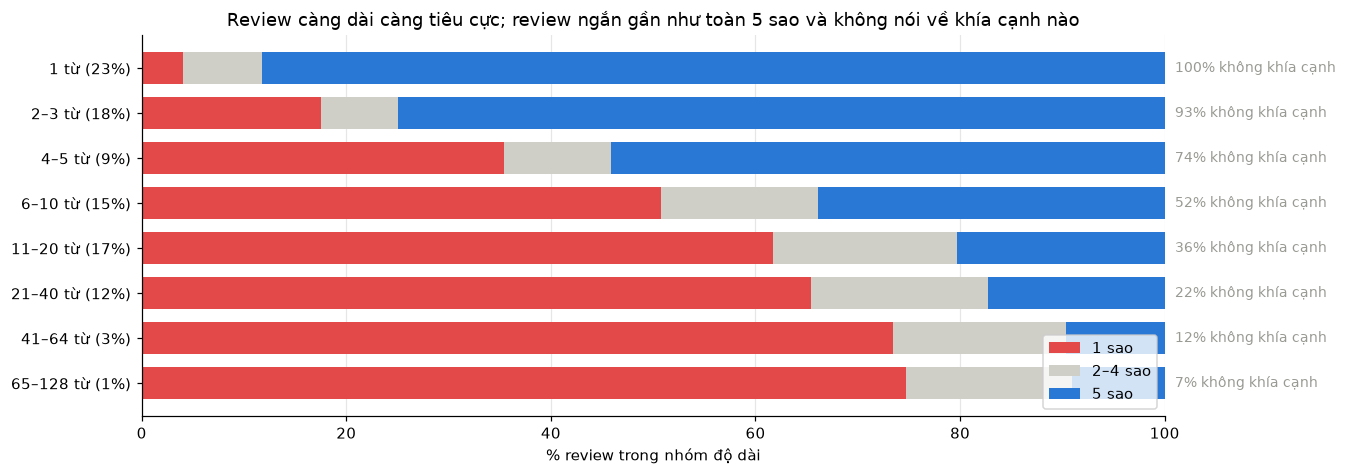

In [12]:
t = facts["text"]
print(f"{t['n_reviews']:,} review · số từ: trung vị {t['words_p50']:.0f}, p90 {t['words_p90']:.0f}, p95 {t['words_p95']:.0f}, p99 {t['words_p99']:.0f}")
print(f"≤ 3 từ: {t['share_le3']:.0%} · ≤ 10 từ: {t['share_le10']:.0%} · > 64 từ: {t['share_gt64']:.1%} · > 128 từ: {t['share_gt128']:.2%}")
tl = pd.read_csv(E / "text_length.csv", encoding="utf-8-sig")
tl = tl[tl.n > 100]
fig, ax = plt.subplots(figsize=(12, 4.5))
y = np.arange(len(tl))
ax.barh(y, tl.pct_1star, color=RED, label="1 sao", height=0.7)
ax.barh(y, tl.pct_mid, left=tl.pct_1star, color="#cfcec7", label="2–4 sao", height=0.7)
ax.barh(y, tl.pct_5star, left=tl.pct_1star + tl.pct_mid, color=BLUE, label="5 sao", height=0.7)
ax.set_yticks(y, [f"{b} từ ({s:.0%})" for b, s in zip(tl.len_bin, tl.share)])
ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("% review trong nhóm độ dài")
for yi, v in zip(y, tl.pct_no_aspect):
    ax.text(101, yi, f"{v:.0f}% không khía cạnh", va="center", fontsize=9, color=GRAY)
ax.set_title("Review càng dài càng tiêu cực; review ngắn gần như toàn 5 sao và không nói về khía cạnh nào")
ax.legend(loc="lower right")
plt.show()

**Nhận xét**
- Review rất ngắn: một nửa có từ 5 từ trở xuống, chỉ 1,4% dài hơn 64 từ.
- Độ dài gần như quyết định số sao. Review 1 từ có 88% là 5 sao; review trên 40 từ có hơn 70% là 1 sao.
- Review ngắn hầu như không chạm khía cạnh nào.

**→ Hành động**
- *Tiền xử lý*: max_len = 64 phủ khoảng 98–99% review.
- *Lấy mẫu gán nhãn*: phân tầng theo **độ dài × số sao × ngân hàng**. Nếu lấy ngẫu nhiên, mẫu sẽ toàn "ok", "tốt".
- *Thuật toán*: báo macro-F1. Kiểm xem mô hình có chỉ học "độ dài → sao" không, bằng một baseline chỉ dùng độ dài.

## 8. Cách viết và khía cạnh

**Câu hỏi:** Cần chuẩn hóa văn bản gì? Khía cạnh nào đủ dữ liệu để làm chỉ số theo ngân hàng–quý (đơn vị của xếp hạng)?

                lang  share  mean_star
              có dấu   81.5       2.95
khác (ngắn, ký hiệu)   12.7       4.80
tiếng Việt không dấu    3.3       4.42
           tiếng Anh    2.6       4.80
Có emoji: 3% · bản lặp nội dung: 44% toàn bộ, 10% với review > 3 từ


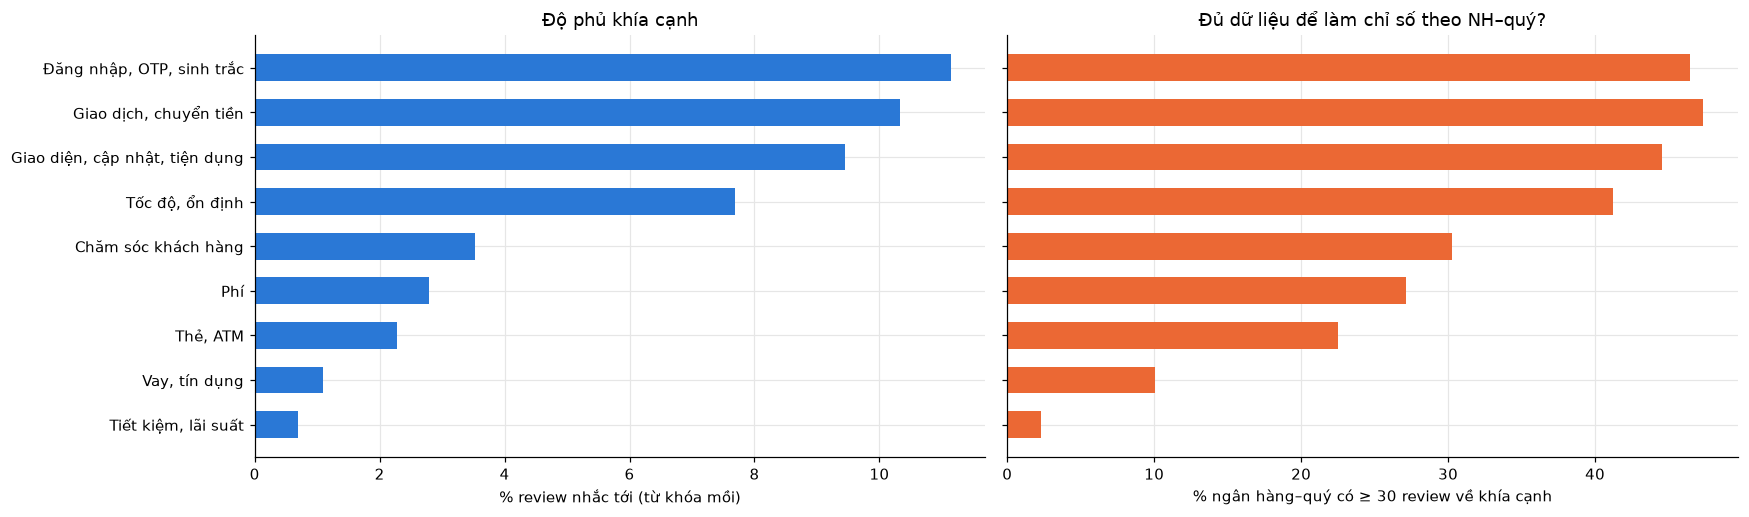

,label,n,share,mean_star,pct_1star,bq_median,bq_share_ge30
1,"Đăng nhập, OTP, sinh trắc",59263,0.111,1.566,75.259,25.0,0.465
0,"Giao dịch, chuyển tiền",54957,0.103,2.345,56.582,26.0,0.474
2,"Giao diện, cập nhật, tiện dụng",50272,0.094,3.063,39.646,22.0,0.445
3,"Tốc độ, ổn định",40863,0.077,1.723,69.241,19.0,0.412
4,Chăm sóc khách hàng,18757,0.035,1.819,73.247,10.0,0.303
6,Phí,14859,0.028,2.126,65.570,7.0,0.271
5,"Thẻ, ATM",12101,0.023,2.113,63.053,6.0,0.225
8,"Vay, tín dụng",5808,0.011,2.570,54.167,4.0,0.100
7,"Tiết kiệm, lãi suất",3730,0.007,3.123,40.161,2.0,0.023


In [13]:
lang = pd.read_csv(E / "text_lang.csv", encoding="utf-8-sig")
print(lang.assign(share=lambda d: (100 * d.share).round(1), mean_star=lambda d: d.mean_star.round(2)).to_string(index=False))
print(f"Có emoji: {t['emoji_share']:.0%} · bản lặp nội dung: {t['dup_extra_share']:.0%} toàn bộ, {t['dup_extra_share_gt3']:.0%} với review > 3 từ")
asp = pd.read_csv(E / "text_aspects.csv", encoding="utf-8-sig").sort_values("share")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
axes[0].barh(asp.label, 100 * asp.share, color=BLUE, height=0.6)
axes[0].set_xlabel("% review nhắc tới (từ khóa mồi)")
axes[0].set_title("Độ phủ khía cạnh")
axes[1].barh(asp.label, 100 * asp.bq_share_ge30, color=ORANGE, height=0.6)
axes[1].set_xlabel("% ngân hàng–quý có ≥ 30 review về khía cạnh")
axes[1].set_title("Đủ dữ liệu để làm chỉ số theo NH–quý?")
plt.tight_layout()
plt.show()
asp[["label", "n", "share", "mean_star", "pct_1star", "bq_median", "bq_share_ge30"]].iloc[::-1].round(3)

**Nhận xét**
- Khoảng 82% review viết có dấu. Số còn lại gồm câu ngắn/ký hiệu (~13%), tiếng Việt không dấu (~3%) và tiếng Anh (~3%).
- Khoảng 65% review không chạm từ khóa khía cạnh nào.
- Các khía cạnh dịch vụ chung (giao dịch, đăng nhập/OTP, giao diện, tốc độ) có mặt ở ~8–11% review, và gần một nửa số NH–quý có từ 30 review trở lên về mỗi khía cạnh.
- **Tiết kiệm/lãi suất chỉ ~0,7%**, trung vị 2 review mỗi NH–quý, chỉ 2% NH–quý đạt 30 review. **Vay ~1%**.

**→ Hành động**
- *Tiền xử lý*: chuẩn hóa Unicode, giữ emoji (mang cảm xúc), không bỏ review không dấu. Thử **ViSoBERT** (học trên văn bản mạng xã hội) cạnh **PhoBERT** (cần tách từ).
- *Nhãn*: thêm lớp "chung / không khía cạnh".
- *Hướng đi*: **không làm chỉ số khía cạnh tiết kiệm theo NH–quý**, vì quá thưa. Tầng xếp hạng dùng các khía cạnh dịch vụ chung, gộp nhiều quý và co rút Bayes.

# Phần C. Tổng hợp: phát hiện → hành động

| Loại hành động (video 1) | Phát hiện | Hành động |
|---|---|---|
| **Làm sạch** | Ngoại lai dồn vào NVB, nhưng là số thật | Giữ NVB; dùng MAE, Spearman, winsorize; báo kết quả có/không có NVB |
| **Làm sạch** | 46% review trùng nội dung, 19 review trống | Bỏ trùng trước khi chia train/test, bỏ review trống |
| **Xử lý phân phối lệch** | ~4/10 đặc trưng lệch; thay đổi mục tiêu có đuôi rất dày | Yeo-Johnson + winsorize (fit trên train) cho mô hình tuyến tính/kNN/PCA/TOPSIS; hàm mất mát MAE/Huber |
| **Tạo đặc trưng mới** | Rolloff giải thích ~64% thay đổi COF quý sau | Số riêng từng quý (MAS) + số hạng rolloff |
| **Tạo đặc trưng mới** | Mùa vụ NPL (quý 4), CASA (quý 1); lãi điều hành trễ 1–2 quý | Biến quý trong năm; lãi tái cấp vốn trễ 1, 2 quý |
| **Bỏ đặc trưng / chọn tiêu chí** | Giữa NH: ~74 biến chỉ mang ~8 chiều; trong NH: VIF cao chỉ ở ROE/ROA | Xếp hạng: mỗi cụm một tiêu chí; dự báo: bỏ một trong ROE/ROA |
| **Encode** | Quý trong năm, gói tín dụng chính sách là biến phân loại; sở hữu nhà nước chia 3 bậc | One-hot quý; giữ 0/1 cho gói; sở hữu nhà nước dùng dạng bậc |
| **Phát hiện rò rỉ** | Chia theo quý không purge làm LightGBM "thắng" tới +67% | Walk-forward / kiểm chéo khối có purge; đặc trưng ⚠️ chỉ dùng trễ 1 quý |
| **Chọn thuật toán** | Tín hiệu ít, phi tuyến hiếm, 22 thực thể | Baseline có cấu trúc làm chính; Ridge/LightGBM nông làm mô hình thách thức; không LSTM cho số tài chính |
| **Chọn thuật toán** | Không có cụm thật | Bỏ phân nhóm cứng; dùng kNN cho "ngân hàng tương tự" |
| **Chọn thuật toán (NLP)** | Review ngắn, nhãn lệch 13 lần, độ dài quyết định sao | max_len 64; macro-F1 + trọng số lớp; TF-IDF làm baseline, so với PhoBERT/ViSoBERT |
| **Hướng đi** | Tiết kiệm/vay quá thưa trong review | Chỉ số dịch vụ dùng khía cạnh chung, không làm khía cạnh tiết kiệm theo NH–quý |

**Bước tiếp theo:** đưa các đặc trưng mới vào `crawlers/build_features.py`, rồi chạy lại walk-forward để chốt mô hình cho từng chỉ tiêu × tầm.